# Segurança pública inteligente em São Paulo: classificação de ocorrências com MLP

**Global Solution 2026.2 - Aprendizado Profundo com Redes Neurais Convolucionais - FIAP**

| Integrante | RM |
|---|---|
| João Vitor Anunciação Oliveira | RM567539 |
| Paulo Ribeiro Marinho | RM567459 |

**Objetivo:** treinar e comparar redes MLP que classificam uma ocorrência de subtração de celular na capital como **roubo** ou **furto**, a partir de região, período do dia, dia da semana, tipo de local, marca e quantidade de celulares.

O modelo não prevê se um crime vai acontecer. Ele indica se uma ocorrência já registrada (ou hipotética) é mais compatível com roubo ou com furto.

## 1. Fonte dos dados

- **Fonte:** SSP-SP, Portal de Estatísticas, *Consultas > Bases de Dados*: https://www.ssp.sp.gov.br/estatistica/consultas
- **Base:** *Celulares Subtraídos*, arquivo `CelularesSubtraidos_2025.xlsx` (boletins registrados em 2025), com 383.635 linhas e 55 colunas.

A base foi escolhida porque traz, em cada boletim, a natureza do crime, o local do fato, o horário e o tipo de local. Segundo a própria SSP, ela é bruta: um boletim pode aparecer em várias linhas (uma por objeto ou crime), por isso as linhas são agrupadas por boletim mais adiante.

In [1]:
import os
os.environ.setdefault("KERAS_BACKEND", "torch")

import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import keras
from keras import layers

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
)

ARQUIVO_SSP = "../dados/CelularesSubtraidos_2025.xlsx"
ARQUIVO_AMOSTRA = "../dados/amostra_celulares_capital_2025.csv"
URL_AMOSTRA = "https://raw.githubusercontent.com/snwvlr/global-solution-aprendizado-profundo/main/dados/amostra_celulares_capital_2025.csv"
PASTA_MODELO = "../modelo"
PASTA_FIGURAS = "../relatorio/img"
os.makedirs(PASTA_MODELO, exist_ok=True)
os.makedirs(PASTA_FIGURAS, exist_ok=True)

SEED = 42
TAMANHO_AMOSTRA = 20000

pd.set_option("display.max_columns", 60)
print("Keras", keras.__version__, "| backend:", keras.backend.backend())

Keras 3.15.1 | backend: torch


In [2]:
def salvar_figura(nome):
    plt.savefig(f"{PASTA_FIGURAS}/{nome}.png", dpi=150, bbox_inches="tight")

### 1.1 Carregar a base bruta

Se o arquivo da SSP não estiver em `dados/`, o notebook usa a amostra já preparada que está no repositório (`amostra_celulares_capital_2025.csv`). Abrindo só o notebook no Colab, sem a pasta `dados/`, a amostra é baixada direto do GitHub.

In [3]:
# sem a planilha da SSP na pasta, o notebook pula a preparação e usa a amostra do repositório
if os.path.exists(ARQUIVO_SSP):
    bruta = pd.read_excel(ARQUIVO_SSP, sheet_name="CELULAR_2025")
    print("Base bruta:", bruta.shape)
else:
    bruta = None
    print("Planilha da SSP não encontrada: o notebook vai usar a amostra já preparada")

Base bruta: (383635, 55)


In [4]:
if bruta is not None:
    display(bruta.head(3))

,ID_DELEGACIA,NOME_DEPARTAMENTO,NOME_SECCIONAL,NOME_DELEGACIA,NOME_MUNICIPIO,ANO_BO,NUM_BO,VERSAO,NOME_DEPARTAMENTO_CIRC,NOME_SECCIONAL_CIRC,NOME_DELEGACIA_CIRC,NOME_MUNICIPIO_CIRC,DATA_OCORRENCIA_BO,HORA_OCORRENCIA,DESCRICAO_APRESENTACAO,DATAHORA_REGISTRO_BO,DATA_COMUNICACAO_BO,DATAHORA_IMPRESSAO_BO,DESCR_PERIODO,AUTORIA_BO,FLAG_INTOLERANCIA,TIPO_INTOLERANCIA,FLAG_FLAGRANTE,FLAG_STATUS,DESC_LEI,FLAG_ATO_INFRACIONAL,RUBRICA,DESCR_CONDUTA,DESDOBRAMENTO,CIRCUNSTANCIA,DESCR_TIPOLOCAL,DESCR_SUBTIPOLOCAL,CIDADE,BAIRRO,CEP,LOGRADOURO_VERSAO,LOGRADOURO,NUMERO_LOGRADOURO,LATITUDE,LONGITUDE,CONT_OBJETO,DESCR_MODO_OBJETO,DESCR_TIPO_OBJETO,DESCR_SUBTIPO_OBJETO,DESCR_UNIDADE,QUANTIDADE_OBJETO,MARCA_OBJETO,FLAG_BLOQUEIO,FLAG_DESBLOQUEIO,MES_REGISTRO_BO,ANO_REGISTRO_BO,CMD,BTL,CIA,CD_IBGE
0,900020,DIPOL - DEPTO DE INTELIGENCIA,DELEGACIA ELETRONICA,DELEGACIA ELETRONICA,S.PAULO,2025,AA1691,1,DECAP,DEL.SEC.1º CENTRO,01º D.P. SE,S.PAULO,2024-12-31,18:30:00,Pela Parte Interessada,2025-01-01,2025-01-01,2025-01-01,NaN,D,N,NaN,N,CONSUMADO,Código Penal,N,Roubo (art. 157),Outros,NaN,NaN,Via Pública,Via Pública,S.PAULO,LIBERDADE,1514001.0,1,RUA GLICÉRIO,671.0,-23.558166,-46.630172,1008550122,Subtraído,Telecomunicação,Telefone Celular,NaN,1,Xiaomi,S,N,1,2025,CPA/M-1,7ºBPM/M,3ªCIA_4ªCIA,3550308
1,900021,DIPOL - DEPTO DE INTELIGENCIA,DELEGACIA ELETRONICA,DELEGACIA ELETRONICA 1,S.PAULO,2025,AA2064,1,DECAP,DEL.SEC.1º CENTRO,01º D.P. SE,S.PAULO,2024-12-30,15:00:00,Pela Parte Interessada,2025-01-01,2025-01-01,2025-01-01,NaN,D,N,NaN,N,CONSUMADO,Código Penal,N,Furto (art. 155),Outros,NaN,NaN,Via Pública,Via Pública,S.PAULO,SE,1021200.0,1,RUA VINTE E CINCO DE MARCO,1081.0,-23.540202,-46.632154,1008550328,Subtraído,Telecomunicação,Telefone Celular,NaN,1,Apple,S,N,1,2025,CPA/M-1,7ºBPM/M,3ªCIA_4ªCIA,3550308
2,900020,DIPOL - DEPTO DE INTELIGENCIA,DELEGACIA ELETRONICA,DELEGACIA ELETRONICA,S.PAULO,2025,AA2458,1,DECAP,DEL.SEC.1º CENTRO,01º D.P. SE,S.PAULO,2025-01-01,04:30:00,Pela Parte Interessada,2025-01-01,2025-01-01,2025-01-01,NaN,D,N,NaN,N,CONSUMADO,Código Penal,N,Roubo (art. 157),Outros,NaN,NaN,Via Pública,Via Pública,S.PAULO,BELA VISTA,1314000.0,1,RUA SANTO ANTÔNIO,54.0,-23.549928,-46.640538,1008550572,Subtraído,Telecomunicação,Telefone Celular,NaN,1,Motorola,S,N,1,2025,CPA/M-1,7ºBPM/M,3ªCIA_4ªCIA,3550308


## 2. Recorte geográfico: fatos ocorridos na capital

`NOME_MUNICIPIO` é o município da delegacia que registrou o boletim, não o do fato. Um boletim feito na Delegacia Eletrônica, por exemplo, aparece como São Paulo mesmo quando o crime foi em outra cidade. Por isso o filtro usa os campos do local do fato: `NOME_MUNICIPIO_CIRC` e `CIDADE` iguais a `S.PAULO`.

In [5]:
if bruta is not None:
    registro = bruta["NOME_MUNICIPIO"] == "S.PAULO"
    fato = (bruta["NOME_MUNICIPIO_CIRC"] == "S.PAULO") & (bruta["CIDADE"] == "S.PAULO")
    print("Linhas registradas em delegacias da capital:", registro.sum())
    print("Linhas com fato ocorrido na capital:        ", fato.sum())
    print("Registradas na capital, mas com fato em outra cidade:", (registro & ~fato).sum())

    capital = bruta[fato].copy()
    print("\nLinhas após o recorte:", capital.shape)

Linhas registradas em delegacias da capital: 216129
Linhas com fato ocorrido na capital:         215962
Registradas na capital, mas com fato em outra cidade: 167

Linhas após o recorte: (215962, 55)


## 3. Definição da variável-alvo

A coluna `RUBRICA` define o rótulo: `Roubo (art. 157)` vira **1** e `Furto (art. 155)` vira **0**. As outras rubricas (perda, estelionato etc.) saem da base. As linhas são agrupadas por boletim (`ANO_BO + NUM_BO + ID_DELEGACIA`), e boletins com roubo e furto ao mesmo tempo são descartados por serem ambíguos.

In [6]:
if bruta is not None:
    print(capital["RUBRICA"].value_counts().head(6))

    capital = capital[capital["RUBRICA"].isin(["Roubo (art. 157)", "Furto (art. 155)"])]
    chave = ["ANO_BO", "NUM_BO", "ID_DELEGACIA"]

    # boletim com roubo e furto ao mesmo tempo é ambíguo e sai da base
    rubricas_por_bo = capital.groupby(chave)["RUBRICA"].nunique()
    ambiguos = rubricas_por_bo[rubricas_por_bo > 1].index
    print("\nBoletins com roubo e furto ao mesmo tempo (descartados):", len(ambiguos))
    capital = capital[~capital.set_index(chave).index.isin(ambiguos)]

    # cada boletim vira uma linha, guardando quantos celulares diferentes ele tinha
    qtd = capital.groupby(chave)["CONT_OBJETO"].nunique().rename("QTD_CELULARES")
    boletins = capital.groupby(chave).first().join(qtd).reset_index()

    boletins["roubo"] = (boletins["RUBRICA"] == "Roubo (art. 157)").astype(int)
    print("Linhas antes do agrupamento:", len(capital), "| boletins únicos:", len(boletins))

RUBRICA
Furto (art. 155)                              106365
Roubo (art. 157)                               77293
Perda/Extravio                                 22123
Localização/Apreensão e Entrega de veículo      2586
Estelionato (art. 171)                          1050
Outros não criminal                              812
Name: count, dtype: int64



Boletins com roubo e furto ao mesmo tempo (descartados): 44


Linhas antes do agrupamento: 183517 | boletins únicos: 161477


## 4. Escolha dos atributos

| Atributo | Origem na base | Motivo |
|---|---|---|
| `regiao` | `NOME_DELEGACIA_CIRC` | A proporção de roubos muda muito entre regiões. É mais confiável que o bairro digitado, que tem 1.888 grafias. |
| `periodo` | `HORA_OCORRENCIA` ou `DESCR_PERIODO` | Metade dos boletins tem a hora e a outra metade só o período; os dois viram madrugada, manhã, tarde e noite. |
| `dia_semana` | `DATA_OCORRENCIA_BO` | O movimento de pessoas muda ao longo da semana. |
| `local` | `DESCR_SUBTIPOLOCAL` | Separa via pública, metrô, ônibus etc. Ficam os 15 mais frequentes e o resto vira `Outros`. |
| `marca` | `MARCA_OBJETO` | Apple, Samsung, Motorola, Xiaomi ou `Outras`. |
| `qtd_celulares` | objetos do boletim | Mais de um celular costuma indicar abordagem a um grupo. Limitada a 5. |

**Fora do modelo:**

- `RUBRICA`, `DESCR_CONDUTA` e `DESDOBRAMENTO`, que revelam a classe (data leakage);
- campos que só existem depois do fato, como autoria, flagrante e bloqueio do aparelho;
- endereço, coordenadas e número do boletim, por privacidade.

Também ficam só os fatos ocorridos em 2025.

In [7]:
DIAS = ["Segunda", "Terça", "Quarta", "Quinta", "Sexta", "Sábado", "Domingo"]
PERIODO_SSP = {"De madrugada": "Madrugada", "Pela manhã": "Manhã", "A tarde": "Tarde", "A noite": "Noite"}


def calcular_periodo(linha):
    hora = linha["HORA_OCORRENCIA"]
    if hasattr(hora, "hour"):
        return ["Madrugada", "Manhã", "Tarde", "Noite"][hora.hour // 6]
    # sem a hora, vale o período escrito no boletim; "Em hora incerta" vira nulo
    return PERIODO_SSP.get(linha["DESCR_PERIODO"])


if bruta is not None:
    data = pd.to_datetime(boletins["DATA_OCORRENCIA_BO"], errors="coerce")
    boletins = boletins[data.dt.year == 2025]
    data = data[data.dt.year == 2025]

    locais_frequentes = boletins["DESCR_SUBTIPOLOCAL"].value_counts().head(15).index
    marcas = ["Apple", "Samsung", "Motorola", "Xiaomi"]

    dados = pd.DataFrame({
        "regiao": boletins["NOME_DELEGACIA_CIRC"],
        "periodo": boletins.apply(calcular_periodo, axis=1),
        "dia_semana": data.dt.dayofweek.map(lambda d: DIAS[d]),
        "local": boletins["DESCR_SUBTIPOLOCAL"].where(boletins["DESCR_SUBTIPOLOCAL"].isin(locais_frequentes), "Outros"),
        "marca": boletins["MARCA_OBJETO"].where(boletins["MARCA_OBJETO"].isin(marcas), "Outras"),
        "qtd_celulares": boletins["QTD_CELULARES"].clip(upper=5),
        "roubo": boletins["roubo"],
    })

    # porto, aeroporto e delegacia eletrônica não são regiões da cidade
    especiais = boletins["NOME_SECCIONAL_CIRC"].isin(["DIV.POL.PORTO/AERO/PROT.TURISTA", "DELEGACIA ELETRONICA"])
    print("Período desconhecido (hora incerta ou vazio):", dados["periodo"].isna().sum())
    print("Unidades especiais:", especiais.sum())
    dados = dados[dados["periodo"].notna() & ~especiais.values]
    print("Boletins disponíveis para o modelo:", dados.shape)

Período desconhecido (hora incerta ou vazio): 486
Unidades especiais: 26
Boletins disponíveis para o modelo: (159076, 7)


## 5. Amostra de trabalho

Seguindo a sugestão do enunciado (10 a 20 mil registros), foram sorteados **20.000 boletins** de forma estratificada, mantendo a proporção de roubos da base completa. A amostra é salva em CSV para o notebook rodar sem o arquivo original.

In [8]:
if bruta is not None:
    # sorteio estratificado: mesma proporção de roubos da base inteira
    amostra, _ = train_test_split(dados, train_size=TAMANHO_AMOSTRA, stratify=dados["roubo"], random_state=SEED)
    amostra.to_csv(ARQUIVO_AMOSTRA, index=False)
    print("% de roubo na base completa:", round(dados["roubo"].mean() * 100, 2))

# abrindo só o notebook no Colab não existe a pasta dados, então a amostra vem do GitHub
df = pd.read_csv(ARQUIVO_AMOSTRA if os.path.exists(ARQUIVO_AMOSTRA) else URL_AMOSTRA)
print("Amostra:", df.shape, "| % de roubo:", round(df["roubo"].mean() * 100, 2))
df.head()

% de roubo na base completa: 36.97
Amostra: (20000, 7) | % de roubo: 36.97


,regiao,periodo,dia_semana,local,marca,qtd_celulares,roubo
0,12º D.P. PARI,Manhã,Quinta,Via Pública,Apple,1,0
1,14º D.P. PINHEIROS,Noite,Terça,Via Pública,Samsung,1,0
2,26º D.P. SACOMA,Noite,Quinta,Via Pública,Apple,1,1
3,51º D.P. RIO PEQUENO,Madrugada,Sábado,Via Pública,Apple,1,1
4,101º D.P. JDIM IMBUIAS,Noite,Sexta,Via Pública,Apple,1,1


## 6. Exploração da amostra

In [9]:
print("Valores ausentes por coluna:")
print(df.isna().sum())
print("\nLinhas duplicadas:", df.duplicated().sum())
print("(duplicatas aqui são boletins diferentes com as mesmas características, por isso são mantidas)")
print("\nCategorias por atributo:")
print(df.drop(columns=["roubo", "qtd_celulares"]).nunique())

Valores ausentes por coluna:
regiao           0
periodo          0
dia_semana       0
local            0
marca            0
qtd_celulares    0
roubo            0
dtype: int64

Linhas duplicadas: 8176
(duplicatas aqui são boletins diferentes com as mesmas características, por isso são mantidas)

Categorias por atributo:
regiao        94
periodo        4
dia_semana     7
local         15
marca          5
dtype: int64


roubo
Furto    12606
Roubo     7394
Name: count, dtype: int64
roubo
Furto    63.03
Roubo    36.97
Name: count, dtype: float64


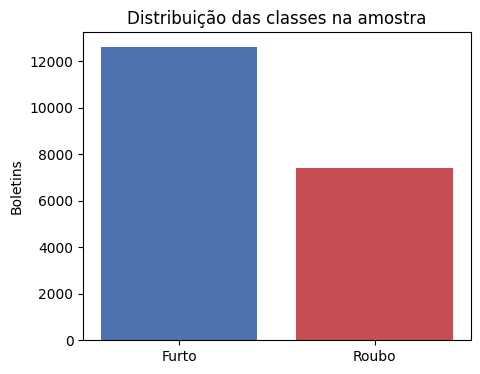

In [10]:
contagem = df["roubo"].map({0: "Furto", 1: "Roubo"}).value_counts()
print(contagem)
print((contagem / len(df) * 100).round(2))

plt.figure(figsize=(5, 4))
plt.bar(contagem.index, contagem.values, color=["#4c72b0", "#c44e52"])
plt.ylabel("Boletins")
plt.title("Distribuição das classes na amostra")
salvar_figura("classes")
plt.show()

As classes são desbalanceadas (37% roubo e 63% furto). Responder sempre "furto" já daria 63% de acurácia, por isso a comparação usa principalmente o **F1-score da classe roubo**.

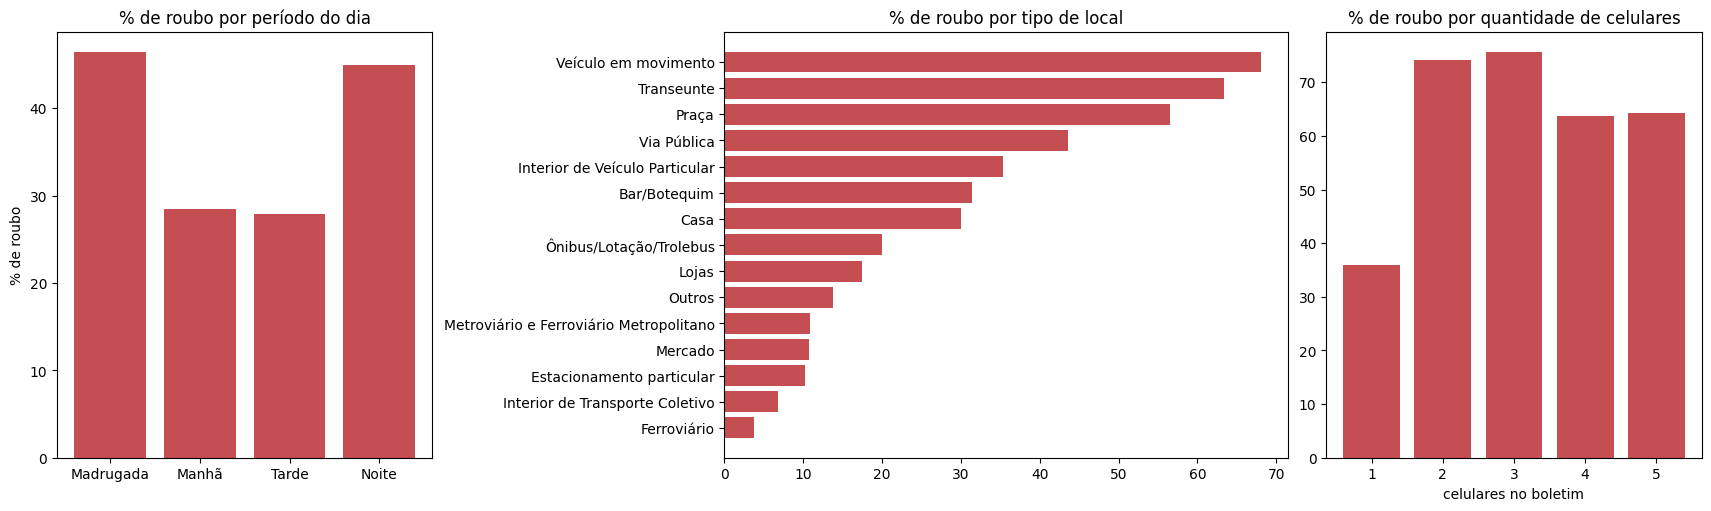

In [11]:
fig, eixos = plt.subplots(1, 3, figsize=(17, 5), width_ratios=[1, 1.5, 1], layout="constrained")

ordem_periodo = ["Madrugada", "Manhã", "Tarde", "Noite"]
taxa = df.groupby("periodo")["roubo"].mean().reindex(ordem_periodo) * 100
eixos[0].bar(taxa.index, taxa.values, color="#c44e52")
eixos[0].set_title("% de roubo por período do dia")
eixos[0].set_ylabel("% de roubo")

taxa = df.groupby("local")["roubo"].mean().sort_values() * 100
eixos[1].barh(taxa.index, taxa.values, color="#c44e52")
eixos[1].set_title("% de roubo por tipo de local")

taxa = df.groupby("qtd_celulares")["roubo"].mean() * 100
eixos[2].bar(taxa.index.astype(str), taxa.values, color="#c44e52")
eixos[2].set_title("% de roubo por quantidade de celulares")
eixos[2].set_xlabel("celulares no boletim")

salvar_figura("exploracao")
plt.show()

In [12]:
por_regiao = df.groupby("regiao")["roubo"].agg(["mean", "size"])
por_regiao = por_regiao[por_regiao["size"] >= 100].sort_values("mean")
print("Regiões com menor % de roubo:")
print((por_regiao.head(5)["mean"] * 100).round(1))
print("\nRegiões com maior % de roubo:")
print((por_regiao.tail(5)["mean"] * 100).round(1))

Regiões com menor % de roubo:
regiao
02º D.P. BOM RETIRO     11.4
78º D.P. JARDINS        14.0
65º D.P. ARTUR ALVIM    17.7
05º D.P. ACLIMACAO      18.5
12º D.P. PARI           20.5
Name: mean, dtype: float64

Regiões com maior % de roubo:
regiao
75º D.P. JARDIM ARPOADOR    62.4
69º D.P. TEOTONIO VILELA    65.1
37º D.P. CAMPO LIMPO        66.2
100º D.P. JDIM HERCULANO    75.8
47º D.P. CAPAO REDONDO      79.1
Name: mean, dtype: float64


**O que a exploração mostra:**

- À noite e de madrugada há mais roubos (cerca de 45%) do que de manhã e à tarde (cerca de 28%).
- No metrô, trem e ônibus quase tudo é furto; em "Transeunte" e "Veículo em movimento" a maioria é roubo.
- Boletins com dois ou mais celulares são, na maioria, roubo.
- Há regiões com menos de 15% de roubos e outras com mais de 60%.
- Dia da semana e marca mudam pouco a proporção.

## 7. Divisão em treino, validação e teste

70% treino, 15% validação e 15% teste, com `stratify` para manter a proporção das classes. O teste só é usado no final, depois da escolha da arquitetura.

In [13]:
X = df.drop(columns=["roubo"])
y = df["roubo"]

X_train, X_temp, y_train, y_temp = train_test_split(X, y, test_size=0.30, random_state=SEED, stratify=y)
X_val, X_test, y_val, y_test = train_test_split(X_temp, y_temp, test_size=0.50, random_state=SEED, stratify=y_temp)

for nome, alvo in [("Treino", y_train), ("Validação", y_val), ("Teste", y_test)]:
    print(f"{nome:10s} {len(alvo):6d} linhas | % roubo: {alvo.mean() * 100:.2f}")

Treino      14000 linhas | % roubo: 36.97
Validação    3000 linhas | % roubo: 36.97
Teste        3000 linhas | % roubo: 36.97


## 8. Pré-processamento

- Categóricos: **One-Hot Encoding**, para não criar uma ordem falsa entre regiões ou locais.
- `qtd_celulares`: **StandardScaler**.

O `ColumnTransformer` é ajustado só no treino e depois aplicado na validação e no teste, para não vazar informação.

In [14]:
numericas = ["qtd_celulares"]
categoricas = ["regiao", "periodo", "dia_semana", "local", "marca"]

preprocess = ColumnTransformer([
    ("num", StandardScaler(), numericas),
    ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), categoricas),
])

# fit só no treino, para não vazar informação da validação e do teste
X_train_prep = preprocess.fit_transform(X_train).astype("float32")
X_val_prep = preprocess.transform(X_val).astype("float32")
X_test_prep = preprocess.transform(X_test).astype("float32")

print("Entradas da rede depois do pré-processamento:", X_train_prep.shape[1])
print(X_train_prep.shape, X_val_prep.shape, X_test_prep.shape)

Entradas da rede depois do pré-processamento: 126
(14000, 126) (3000, 126) (3000, 126)


## 9. Funções de criação, treino e avaliação

- **Camadas ocultas:** `Dense` com **ReLU**, que treina bem em redes com várias camadas.
- **Saída:** 1 neurônio com **sigmoid**, que devolve a probabilidade de ser roubo.
- **Perda:** `binary_crossentropy`, própria para classificação binária.
- **Otimizador:** **Adam** com `learning_rate = 0.001`.
- **Batch size:** 32.

A seed é fixada antes de cada modelo para a comparação ser justa.

In [15]:
def criar_mlp(camadas, dropout=0.0, l2=0.0):
    keras.utils.set_random_seed(SEED)
    modelo = keras.Sequential([layers.Input(shape=(X_train_prep.shape[1],))])
    for neuronios in camadas:
        regularizador = keras.regularizers.l2(l2) if l2 else None
        modelo.add(layers.Dense(neuronios, activation="relu", kernel_regularizer=regularizador))
        if dropout:
            modelo.add(layers.Dropout(dropout))
    modelo.add(layers.Dense(1, activation="sigmoid"))
    modelo.compile(
        optimizer=keras.optimizers.Adam(learning_rate=0.001),
        loss="binary_crossentropy",
        metrics=["accuracy"],
    )
    return modelo


def treinar(nome, modelo, epochs, parada_antecipada=False, pesos_classes=None):
    callbacks = []
    if parada_antecipada:
        callbacks.append(keras.callbacks.EarlyStopping(monitor="val_loss", patience=6, restore_best_weights=True))
    history = modelo.fit(
        X_train_prep, y_train.values,
        validation_data=(X_val_prep, y_val.values),
        epochs=epochs,
        batch_size=32,
        class_weight=pesos_classes,
        callbacks=callbacks,
        verbose=0,
    )
    h = history.history
    print(f"{nome}: {len(h['loss'])} épocas")
    print(f"  loss treino final: {h['loss'][-1]:.4f} | val_loss final: {h['val_loss'][-1]:.4f} | melhor val_loss: {min(h['val_loss']):.4f}")
    return history


def avaliar(modelo, X_prep, y_real):
    prob = modelo.predict(X_prep, verbose=0).ravel()
    pred = (prob >= 0.5).astype(int)
    return {
        "accuracy": accuracy_score(y_real, pred),
        "precision": precision_score(y_real, pred, zero_division=0),
        "recall": recall_score(y_real, pred, zero_division=0),
        "f1": f1_score(y_real, pred, zero_division=0),
    }


modelos, historicos, resultados = {}, {}, {}

## 10. Experimentos com arquiteturas

A tabela mostra o que muda em cada arquitetura em relação à anterior:

| # | Arquitetura | O que muda |
|---|---|---|
| 1 | 32-16 | ponto de partida, como nas aulas |
| 2 | 128-64-32 | mais camadas e neurônios (40 épocas) |
| 3 | 128-64-32 + Dropout 0,3 + L2 + EarlyStopping | regularização para conter o overfitting da 2 |
| 4 | 64-32 + Dropout 0,2 + EarlyStopping + pesos de classe | rede menor, Dropout menor, sem L2 e com peso maior para roubo, a classe minoritária |

### Arquitetura 1: 32-16 (referência)

In [16]:
nome = "Arq. 1: 32-16"
modelos[nome] = criar_mlp([32, 16])
modelos[nome].summary()
historicos[nome] = treinar(nome, modelos[nome], epochs=30)
resultados[nome] = avaliar(modelos[nome], X_val_prep, y_val)
resultados[nome]

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 32)             │         4,064 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,609 (18.00 KB)

 Trainable params: 4,609 (18.00 KB)

 Non-trainable params: 0 (0.00 B)

Arq. 1: 32-16: 30 épocas
  loss treino final: 0.4581 | val_loss final: 0.6134 | melhor val_loss: 0.5508


{'accuracy': 0.6896666666666667,
 'precision': 0.5807622504537205,
 'recall': 0.5770964833183048,
 'f1': 0.5789235639981909}

### Arquitetura 2: 128-64-32 (mais capacidade)

In [17]:
nome = "Arq. 2: 128-64-32"
modelos[nome] = criar_mlp([128, 64, 32])
modelos[nome].summary()
historicos[nome] = treinar(nome, modelos[nome], epochs=40)
resultados[nome] = avaliar(modelos[nome], X_val_prep, y_val)
resultados[nome]

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_3 (Dense)                 │ (None, 128)            │        16,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 26,625 (104.00 KB)

 Trainable params: 26,625 (104.00 KB)

 Non-trainable params: 0 (0.00 B)

Arq. 2: 128-64-32: 40 épocas
  loss treino final: 0.2883 | val_loss final: 1.2159 | melhor val_loss: 0.5533


{'accuracy': 0.6653333333333333,
 'precision': 0.5550891920251836,
 'recall': 0.4770063119927863,
 'f1': 0.513094083414161}

### Arquitetura 3: 128-64-32 com regularização

Mesma rede da 2, com Dropout de 30% depois de cada camada oculta, L2 (`1e-4`) nos pesos e EarlyStopping (para quando a `val_loss` não melhora por 6 épocas e volta aos melhores pesos).

In [18]:
nome = "Arq. 3: 128-64-32 + regularização"
modelos[nome] = criar_mlp([128, 64, 32], dropout=0.3, l2=1e-4)
historicos[nome] = treinar(nome, modelos[nome], epochs=60, parada_antecipada=True)
resultados[nome] = avaliar(modelos[nome], X_val_prep, y_val)
resultados[nome]

Arq. 3: 128-64-32 + regularização: 13 épocas
  loss treino final: 0.5191 | val_loss final: 0.5985 | melhor val_loss: 0.5704


{'accuracy': 0.7256666666666667,
 'precision': 0.676980198019802,
 'recall': 0.4932371505861136,
 'f1': 0.5706833594157538}

### Arquitetura 4: 64-32 com Dropout, EarlyStopping e pesos de classe

Como só 37% dos boletins são roubo, a rede tende a responder furto. Com `class_weight="balanced"`, errar um roubo pesa mais na perda. A rede é menor que a 3 e sem L2, porque mais capacidade não trouxe ganho. Como várias coisas mudam ao mesmo tempo, o resultado da 4 não mostra sozinho o efeito dos pesos de classe.

In [19]:
pesos = compute_class_weight("balanced", classes=np.array([0, 1]), y=y_train.values)
pesos_classes = {0: pesos[0], 1: pesos[1]}
print("Pesos de classe:", {k: round(v, 3) for k, v in pesos_classes.items()})

nome = "Arq. 4: 64-32 + dropout + pesos"
modelos[nome] = criar_mlp([64, 32], dropout=0.2)
modelos[nome].summary()
historicos[nome] = treinar(nome, modelos[nome], epochs=60, parada_antecipada=True, pesos_classes=pesos_classes)
resultados[nome] = avaliar(modelos[nome], X_val_prep, y_val)
resultados[nome]

Pesos de classe: {0: np.float64(0.793), 1: np.float64(1.352)}


Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_11 (Dense)                │ (None, 64)             │         8,128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_12 (Dense)                │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_13 (Dense)                │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 10,241 (40.00 KB)

 Trainable params: 10,241 (40.00 KB)

 Non-trainable params: 0 (0.00 B)

Arq. 4: 64-32 + dropout + pesos: 11 épocas
  loss treino final: 0.5311 | val_loss final: 0.6009 | melhor val_loss: 0.5666


{'accuracy': 0.7113333333333334,
 'precision': 0.6042918454935622,
 'recall': 0.6348061316501352,
 'f1': 0.6191732629727352}

## 11. Comparação na validação

In [20]:
tabela = pd.DataFrame(resultados).T
tabela["épocas"] = [len(historicos[n].history["loss"]) for n in tabela.index]
tabela["melhor val_loss"] = [min(historicos[n].history["val_loss"]) for n in tabela.index]
tabela["val_loss final"] = [historicos[n].history["val_loss"][-1] for n in tabela.index]
tabela = tabela.round(4)
tabela

,accuracy,precision,recall,f1,épocas,melhor val_loss,val_loss final
Arq. 1: 32-16,0.6897,0.5808,0.5771,0.5789,30,0.5508,0.6134
Arq. 2: 128-64-32,0.6653,0.5551,0.4770,0.5131,40,0.5533,1.2159
Arq. 3: 128-64-32 + regularização,0.7257,0.6770,0.4932,0.5707,13,0.5704,0.5985
Arq. 4: 64-32 + dropout + pesos,0.7113,0.6043,0.6348,0.6192,11,0.5666,0.6009


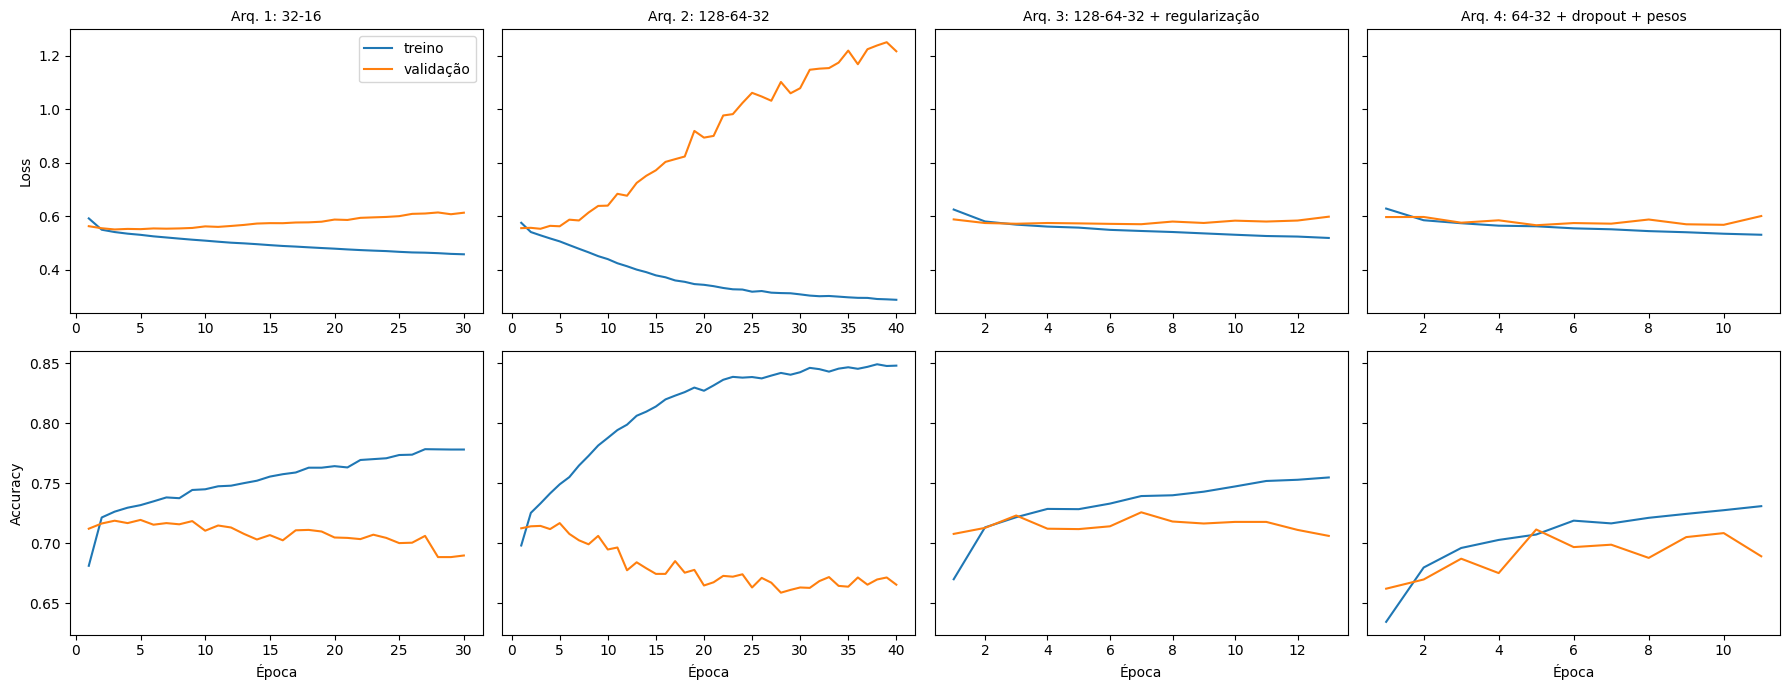

In [21]:
fig, eixos = plt.subplots(2, 4, figsize=(18, 7), sharey="row")
for i, nome in enumerate(historicos):
    h = historicos[nome].history
    epocas = range(1, len(h["loss"]) + 1)
    eixos[0, i].plot(epocas, h["loss"], label="treino")
    eixos[0, i].plot(epocas, h["val_loss"], label="validação")
    eixos[0, i].set_title(nome, fontsize=10)
    eixos[1, i].plot(epocas, h["accuracy"], label="treino")
    eixos[1, i].plot(epocas, h["val_accuracy"], label="validação")
    eixos[1, i].set_xlabel("Época")
eixos[0, 0].set_ylabel("Loss")
eixos[1, 0].set_ylabel("Accuracy")
eixos[0, 0].legend()
plt.tight_layout()
salvar_figura("curvas_arquiteturas")
plt.show()

**Leitura das curvas:**

- **Arq. 1:** a perda de treino continua caindo, mas a `val_loss` sobe depois das primeiras épocas: começo de overfitting.
- **Arq. 2:** a rede decora o treino e a `val_loss` dispara. É o overfitting mais claro, e o F1 também piora.
- **Arq. 3:** a regularização aproxima treino e validação e a acurácia melhora, mas o recall de roubo continua baixo.
- **Arq. 4:** a `val_loss` volta a subir depois da época 5 (começo de overfitting), e o EarlyStopping guarda os pesos dessa época. É a arquitetura com maior recall e F1 de roubo. A perda de treino usa os pesos de classe e a de validação não, então as duas curvas de loss não são diretamente comparáveis.
- Nenhuma mostra underfitting forte: a arquitetura 2 chega a loss 0,29 no treino, então capacidade não é o limite. O limite vem dos atributos, já que a base não registra os detalhes que definem roubo ou furto.

## 12. Modelo escolhido e avaliação final no teste

A escolha usa o **maior F1 da classe roubo na validação**, porque o F1 equilibra precision e recall e não é enganado pelo desbalanceamento.

In [22]:
escolhido = tabela["f1"].idxmax()
modelo_final = modelos[escolhido]
print("Arquitetura escolhida:", escolhido)

y_test_prob = modelo_final.predict(X_test_prep, verbose=0).ravel()
y_test_pred = (y_test_prob >= 0.5).astype(int)
metricas_teste = {
    "accuracy": accuracy_score(y_test, y_test_pred),
    "precision": precision_score(y_test, y_test_pred),
    "recall": recall_score(y_test, y_test_pred),
    "f1": f1_score(y_test, y_test_pred),
}
print({k: round(v, 4) for k, v in metricas_teste.items()})
print()
print(classification_report(y_test, y_test_pred, target_names=["Furto", "Roubo"], digits=3))

Arquitetura escolhida: Arq. 4: 64-32 + dropout + pesos
{'accuracy': 0.6987, 'precision': 0.5875, 'recall': 0.6204, 'f1': 0.6035}

              precision    recall  f1-score   support

       Furto      0.770     0.745     0.757      1891
       Roubo      0.588     0.620     0.604      1109

    accuracy                          0.699      3000
   macro avg      0.679     0.682     0.680      3000
weighted avg      0.702     0.699     0.700      3000



[[1408  483]
 [ 421  688]]


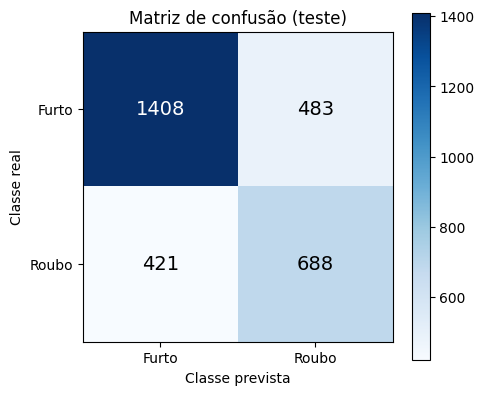

In [23]:
cm = confusion_matrix(y_test, y_test_pred)
print(cm)

fig, eixo = plt.subplots(figsize=(5, 4.5))
imagem = eixo.imshow(cm, cmap="Blues")
for i in range(2):
    for j in range(2):
        eixo.text(j, i, cm[i, j], ha="center", va="center", fontsize=14,
                  color="white" if cm[i, j] > cm.max() / 2 else "black")
eixo.set_xticks([0, 1], ["Furto", "Roubo"])
eixo.set_yticks([0, 1], ["Furto", "Roubo"])
eixo.set_xlabel("Classe prevista")
eixo.set_ylabel("Classe real")
eixo.set_title("Matriz de confusão (teste)")
plt.colorbar(imagem)
salvar_figura("matriz_confusao")
plt.show()

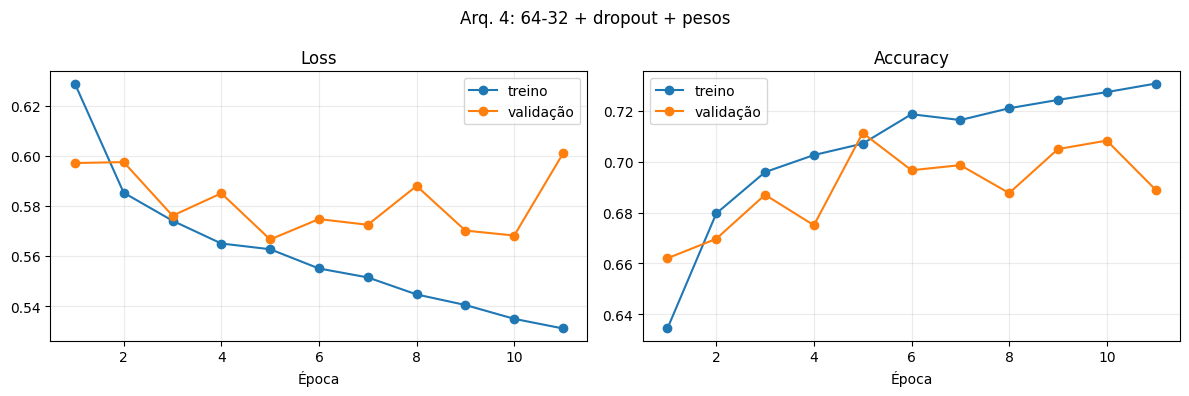

In [24]:
h = historicos[escolhido].history
epocas = range(1, len(h["loss"]) + 1)
fig, eixos = plt.subplots(1, 2, figsize=(12, 4))
eixos[0].plot(epocas, h["loss"], marker="o", label="treino")
eixos[0].plot(epocas, h["val_loss"], marker="o", label="validação")
eixos[0].set_title("Loss")
eixos[1].plot(epocas, h["accuracy"], marker="o", label="treino")
eixos[1].plot(epocas, h["val_accuracy"], marker="o", label="validação")
eixos[1].set_title("Accuracy")
for eixo in eixos:
    eixo.set_xlabel("Época")
    eixo.legend()
    eixo.grid(alpha=0.25)
plt.suptitle(escolhido)
plt.tight_layout()
salvar_figura("curvas_escolhido")
plt.show()

## 13. Exportação do modelo para a aplicação web

O modelo é salvo em `modelo_mlp.keras` e em `modelo_mlp.json` (pesos de cada camada, categorias do One-Hot e média/desvio do StandardScaler). A aplicação web lê o JSON e faz o cálculo da rede com NumPy, sem precisar instalar TensorFlow ou PyTorch no servidor. A última célula confere que o NumPy dá o mesmo resultado do Keras.

In [25]:
modelo_final.save(f"{PASTA_MODELO}/modelo_mlp.keras")

encoder = preprocess.named_transformers_["cat"]
scaler = preprocess.named_transformers_["num"]
camadas_dense = [camada for camada in modelo_final.layers if isinstance(camada, layers.Dense)]

exportado = {
    "arquitetura": escolhido,
    "numericos": {
        nome: {"media": float(scaler.mean_[i]), "desvio": float(scaler.scale_[i])}
        for i, nome in enumerate(numericas)
    },
    "categoricos": {
        nome: [str(c) for c in encoder.categories_[i]]
        for i, nome in enumerate(categoricas)
    },
    "camadas": [
        {
            "pesos": camada.get_weights()[0].tolist(),
            "bias": camada.get_weights()[1].tolist(),
            "ativacao": camada.activation.__name__,
        }
        for camada in camadas_dense
    ],
    "metricas_teste": {k: round(float(v), 4) for k, v in metricas_teste.items()},
    "amostras": {"treino": len(y_train), "validacao": len(y_val), "teste": len(y_test)},
}

with open(f"{PASTA_MODELO}/modelo_mlp.json", "w", encoding="utf-8") as arquivo:
    json.dump(exportado, arquivo, ensure_ascii=False)

tabela.to_csv(f"{PASTA_MODELO}/comparacao_validacao.csv")
print("Camadas exportadas:", [(c["ativacao"], np.array(c["pesos"]).shape) for c in exportado["camadas"]])

Camadas exportadas: [('relu', (126, 64)), ('relu', (64, 32)), ('sigmoid', (32, 1))]


In [26]:
# mesma conta que o site faz, para comparar com o predict() do Keras
def prever_numpy(entrada, modelo_json):
    saida = entrada
    for camada in modelo_json["camadas"]:
        saida = saida @ np.array(camada["pesos"]) + np.array(camada["bias"])
        saida = np.maximum(saida, 0) if camada["ativacao"] == "relu" else 1 / (1 + np.exp(-saida))
    return saida.ravel()


prob_keras = modelo_final.predict(X_test_prep, verbose=0).ravel()
prob_numpy = prever_numpy(X_test_prep.astype("float64"), exportado)
print("Maior diferença entre Keras e NumPy:", np.abs(prob_keras - prob_numpy).max())
print("Mesma classe em todas as amostras de teste:", ((prob_keras >= 0.5) == (prob_numpy >= 0.5)).all())

Maior diferença entre Keras e NumPy: 8.360650405325742e-08
Mesma classe em todas as amostras de teste: True


In [27]:
exemplo = pd.DataFrame([{
    "regiao": "14º D.P. PINHEIROS",
    "periodo": "Noite",
    "dia_semana": "Sexta",
    "local": "Via Pública",
    "marca": "Apple",
    "qtd_celulares": 1,
}])
p_roubo = float(modelo_final.predict(preprocess.transform(exemplo).astype("float32"), verbose=0)[0, 0])
print(f"Roubo: {p_roubo:.1%} | Furto: {1 - p_roubo:.1%}")

Roubo: 58.5% | Furto: 41.5%


**Como interpretar:** o modelo atribui essa probabilidade a cada classe para uma ocorrência com essas características. Ele não diz a chance de acontecer um roubo em Pinheiros numa sexta à noite.

## 14. Conclusões e limitações

**Conclusões**

- A MLP separa roubo de furto acima de uma resposta fixa (accuracy de 0,699 no teste, contra 0,63 de responder sempre furto), usando só informações do registro. O ganho é moderado.
- Aumentar a rede sem regularização (arquitetura 2) causou overfitting. Dropout, L2 e EarlyStopping aproximaram treino e validação, mas a menor `val_loss` continuou sendo a da arquitetura 1.
- A arquitetura 4, com pesos de classe, teve o maior F1 de roubo. Como ela muda várias coisas ao mesmo tempo, não dá para separar o efeito de cada mudança.

**Limitações**

- A base é bruta e não é estatística oficial.
- Os atributos não descrevem a dinâmica do crime (abordagem, arma, número de autores), que é o que define roubo ou furto.
- Só aparecem crimes registrados em boletim.
- O modelo foi treinado só com 2025.
- Com os pesos de classe, a probabilidade de roubo fica puxada para cima; ela serve para comparar ocorrências, não como frequência real.